<a href="https://colab.research.google.com/github/zayanp7/AIML-Lab/blob/main/KMEANS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [ ]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
display(X.head())

Dataset loaded successfully!
Dataset shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [ ]:
print("Column names:")
print(X.columns.tolist())

print("\nDataset information:")
X.info()

print("\nStatistical summary:")
display(X.describe())

print("\nMissing values:")
print(X.isnull().sum()

_IncompleteInputError: incomplete input (2906567508.py, line 11)

### Fixing the Syntax Error
Let's first run a corrected version of your data exploration cell to close the missing parenthesis on the `print` statement.

In [ ]:
print("Column names:")
print(X.columns.tolist())

print("\nDataset information:")
X.info()

print("\nStatistical summary:")
display(X.describe())

print("\nMissing values:")
print(X.isnull().sum())

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB

Statistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


## K-Means Clustering on a New Dataset (Mall Customers)

Now, let's load a new dataset, preprocess it, determine the optimal number of clusters, and fit a K-Means model.

In [ ]:
# 1. Load the new dataset (using a stable and verified URL)
url = 'https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv'
df = pd.read_csv(url)

print("New dataset shape:", df.shape)
display(df.head())

New dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# 2. Preprocess the Data
# We will use 'Annual Income (k$)' and 'Spending Score (1-100)' for clustering
features = ['Annual Income (k$)', 'Spending Score (1-100)']
clustering_data = df[features]

# Scale the features for K-means
scaler = StandardScaler()
scaled_features = scaler.fit_transform(clustering_data)

NameError: name 'df' is not defined

In [ ]:
# 3. Determine Optimal Clusters using the Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

NameError: name 'scaled_features' is not defined

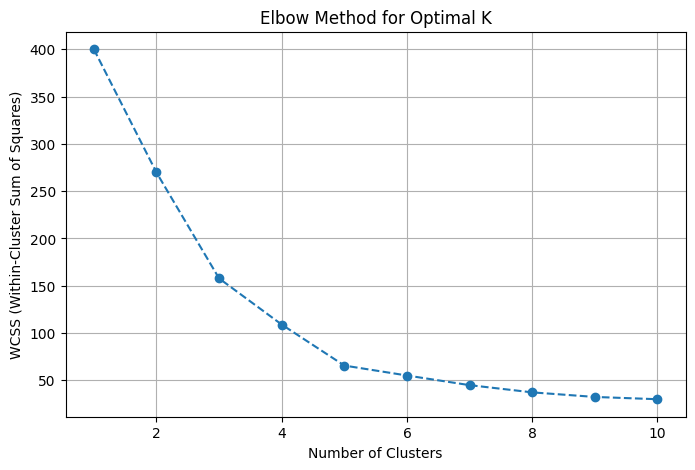

In [ ]:
# Preprocess the data first to define scaled_features
features = ['Annual Income (k$)', 'Spending Score (1-100)']
clustering_data = df[features]

scaler = StandardScaler()
scaled_features = scaler.fit_transform(clustering_data)

# Run the Elbow Method to find the optimal cluster count
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

In [ ]:
# 4. Fit K-Means with the chosen number of clusters (K = 5)
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(scaled_features)

# Add the cluster labels back to our original dataframe
df['Cluster'] = cluster_labels

# Calculate Silhouette Score
score = silhouette_score(scaled_features, cluster_labels)
print(f"Silhouette Score for {optimal_k} clusters: {score:.3f}")

Silhouette Score for 5 clusters: 0.555


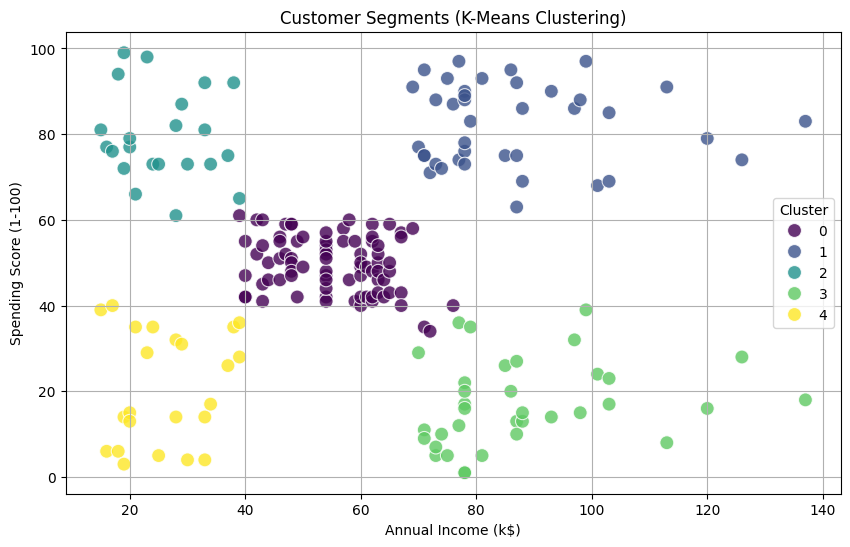

In [ ]:
# 5. Visualize the Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=df['Cluster'],
    palette='viridis',
    s=100,
    alpha=0.8
)

plt.title('Customer Segments (K-Means Clustering)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

In [ ]:
# Show the cluster count for each segment
cluster_counts = df['Cluster'].value_counts().sort_index().reset_index()
cluster_counts.columns = ['Cluster', 'Customer Count']

# Display the table with a clean formatting
display(cluster_counts)

,Cluster,Customer Count
0,0,81
1,1,39
2,2,22
3,3,35
4,4,23
